<a href="https://colab.research.google.com/github/RAVINDUWEERASINGHE2002/ML_Practice2026/blob/main/hirarchicalclustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Mall_Customers.csv to Mall_Customers.csv


In [ ]:
df = pd.read_csv('Mall_Customers.csv')   # or the full path if needed
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
df.shape


(200, 5)

In [ ]:
df.isnull().sum()

,0
CustomerID,0
Genre,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [ ]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
linked = linkage(X_scaled, method='ward')

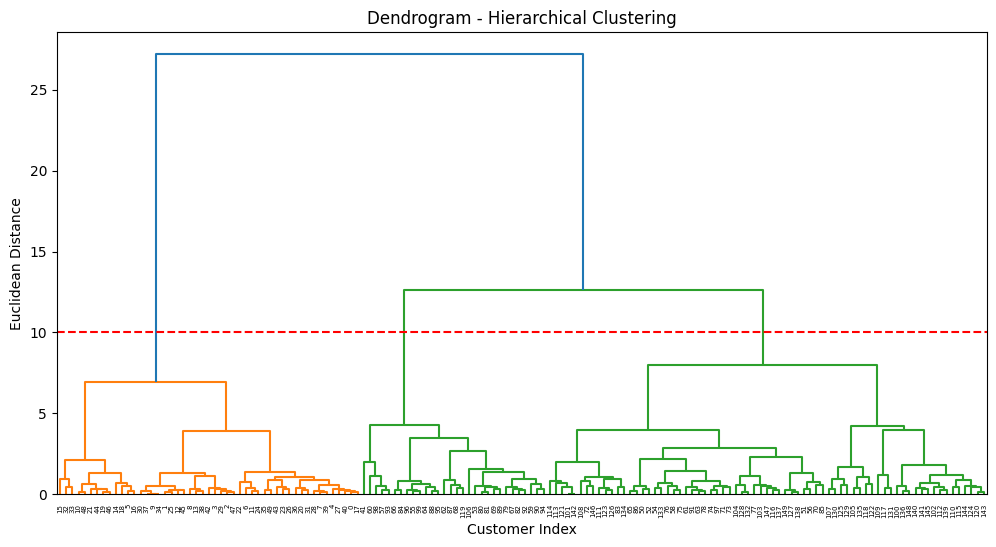

In [ ]:
plt.figure(figsize=(12, 6))
dendrogram(linked)
plt.axhline(y=10, color='r', linestyle='--')
plt.title('Dendrogram - Hierarchical Clustering')
plt.xlabel('Customer Index')
plt.ylabel('Euclidean Distance')
plt.show()

In [ ]:
model = AgglomerativeClustering(
    n_clusters=5,
    metric='euclidean',
    linkage='ward'
)

y_hc = model.fit_predict(X_scaled)

In [ ]:
df['Cluster'] = y_hc
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,3
2,3,Female,20,16,6,4
3,4,Female,23,16,77,3
4,5,Female,31,17,40,4


In [ ]:
df['Cluster'].value_counts().sort_index()

,count
Cluster,
0,32
1,39
2,85
3,21
4,23


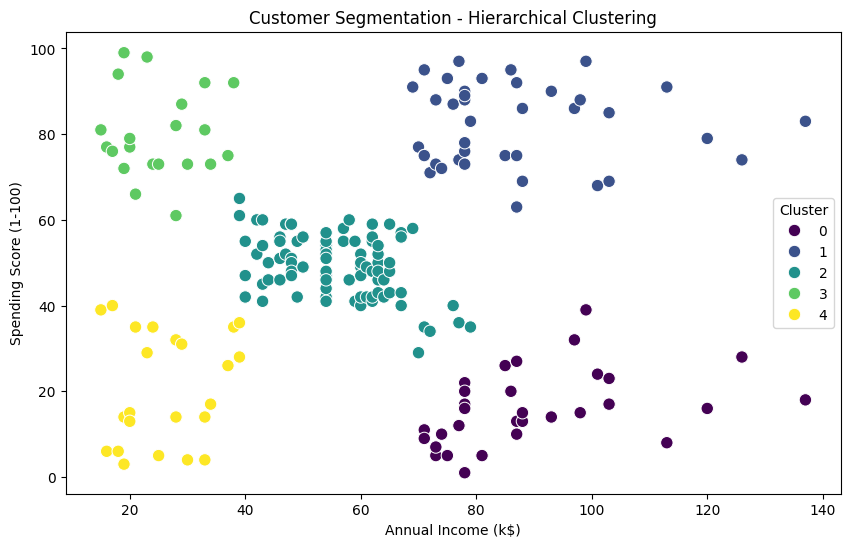

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    data=df,
    palette='viridis',
    s=80
)
plt.title('Customer Segmentation - Hierarchical Clustering')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.show()

In [ ]:
cluster_analysis = df.groupby('Cluster')[['Annual Income (k$)', 'Spending Score (1-100)']].mean()
print(cluster_analysis)

         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                 89.406250               15.593750
1                 86.538462               82.128205
2                 55.811765               49.129412
3                 25.095238               80.047619
4                 26.304348               20.913043


**Task 02**


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Iris.csv to Iris.csv


In [ ]:
df = pd.read_csv('Iris.csv')
df.shape          # (150, 6)
df.isnull().sum() # No missing values

,0
Id,0
SepalLengthCm,0
SepalWidthCm,0
PetalLengthCm,0
PetalWidthCm,0
Species,0


In [ ]:
features = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
X = df[features]

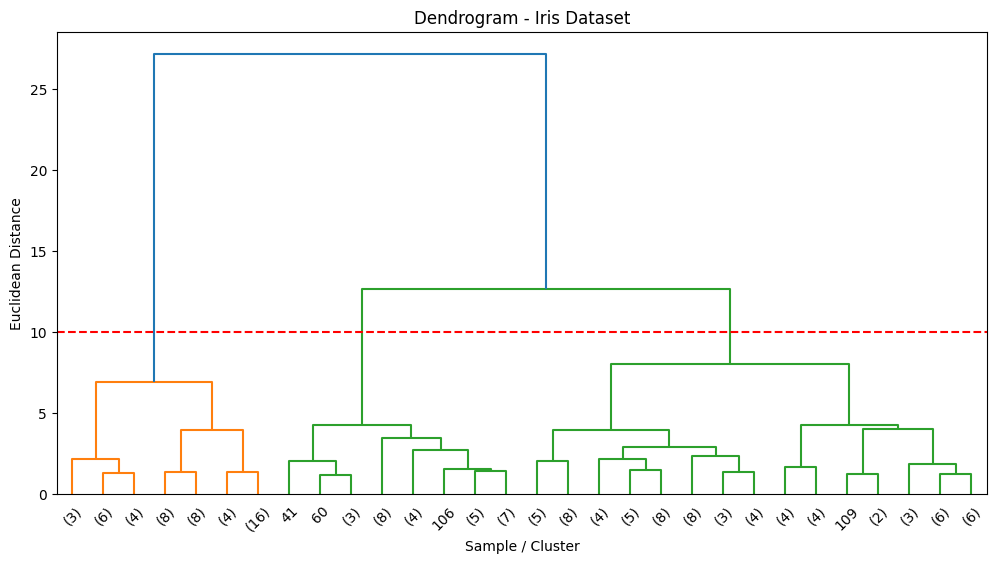

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

linked = linkage(X_scaled, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(linked, truncate_mode='lastp', p=30)
plt.axhline(y=10, color='r', linestyle='--')
plt.title('Dendrogram - Iris Dataset')
plt.xlabel('Sample / Cluster')
plt.ylabel('Euclidean Distance')
plt.show()

In [ ]:
model = AgglomerativeClustering(
    n_clusters=3,
    metric='euclidean',
    linkage='ward'
)

labels = model.fit_predict(X_scaled)
df['Cluster'] = labels

In [ ]:
df['Cluster'].value_counts().sort_index()

,count
Cluster,
0,71
1,49
2,30


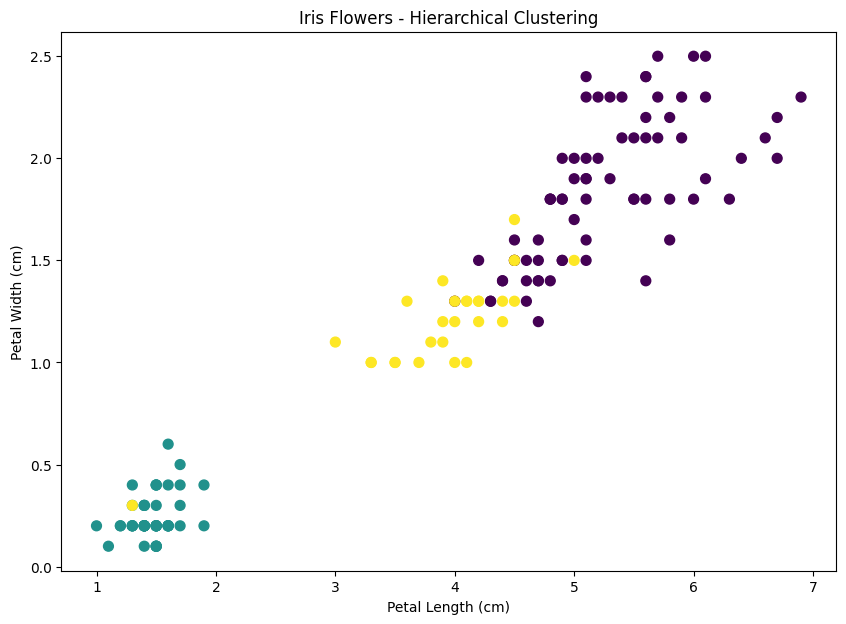

In [ ]:
plt.figure(figsize=(10, 7))
plt.scatter(df['PetalLengthCm'], df['PetalWidthCm'], c=labels, s=50)
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.title('Iris Flowers - Hierarchical Clustering')
plt.show()

In [ ]:
pd.crosstab(df['Cluster'], df['Species'])

Species,Iris-setosa,Iris-versicolor,Iris-virginica
Cluster,,,
0,0,23,48
1,49,0,0
2,1,27,2
